# full paper database analysis

In [9]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, select, func
from sqlalchemy.orm import aliased, sessionmaker

from postgres.model import Citation, Paper

## database

In [2]:
def init_session():
    load_dotenv()

    engine = create_engine(
        f"postgresql+psycopg://{os.getenv('POSTGRES_USER')}:"
        f"{os.getenv('POSTGRES_PASS')}@localhost/"
        f"{os.getenv('POSTGRES_DB')}",
        pool_pre_ping=True,
    )

    return sessionmaker(bind=engine)()

## xlsx

In [12]:
def prepare_count_score_data(
    session,
    seed_file="sample/seed_papers_final.xlsx",
    output_file="sample/count_score_analysis.xlsx",
    alpha=0.2,
    beta=0.5,
):
    seed_df = pd.read_excel(seed_file)
    seed_df["id"] = seed_df["id"].astype("int64")

    # 这里只做候选集筛选，不作为最终 count
    seed_df = seed_df[
        (seed_df["valid_citation_count"] > 10)
        & (seed_df["valid_citation_count"] < 100)
    ].copy()

    CitingPaper = aliased(Paper)
    CitedPaper = aliased(Paper)

    statement = (
        select(
            Citation.citing_corpus_id.label("citing_id"),
            Citation.cited_corpus_id.label("cited_id"),
            Citation.contexts.label("contexts"),
            Citation.cross_score.label("cross_score"),
            Citation.llm_score.label("llm_score"),
            Citation.author_independence.label(
                "author_independence"
            ),
            CitingPaper.title.label("citing_title"),
            CitingPaper.year.label("citing_year"),
            CitingPaper.publication_date.label(
                "citing_publication_date"
            ),
            CitedPaper.title.label("cited_title"),
        )
        .join(
            CitingPaper,
            CitingPaper.corpus_id
            == Citation.citing_corpus_id,
        )
        .join(
            CitedPaper,
            CitedPaper.corpus_id
            == Citation.cited_corpus_id,
        )
        .where(
            Citation.cited_corpus_id.in_(
                seed_df["id"].tolist()
            ),
            # 必须具有有效 citation context
            Citation.contexts.is_not(None),
            Citation.contexts != [],

            # citing 和 cited 都必须具有有效摘要
            CitingPaper.abstract.is_not(None),
            CitedPaper.abstract.is_not(None),

            func.length(
                func.trim(CitingPaper.abstract)
            ) > 0,

            func.length(
                func.trim(CitedPaper.abstract)
            ) > 0,
        )
    )

    rows = session.execute(statement).all()

    citation_df = pd.DataFrame(
        [dict(row._mapping) for row in rows]
    )

    if citation_df.empty:
        raise ValueError("No citation records found.")

    # 只保留具有有效 citation context 的数据库记录
    citation_df = citation_df[
        citation_df["contexts"].map(bool)
    ].copy()

    required_scores = [
        "cross_score",
        "llm_score",
        "author_independence",
    ]

    missing = citation_df[
        required_scores
    ].isna().any(axis=1)

    excluded_df = citation_df.loc[
        missing
    ].copy()

    if not excluded_df.empty:
        print(
            f"Excluded {len(excluded_df)} citation(s) "
            "with incomplete scores."
        )

        display(
            excluded_df[
                [
                    "citing_id",
                    "cited_id",
                    "citing_title",
                    "cited_title",
                    "cross_score",
                    "llm_score",
                    "author_independence",
                ]
            ]
        )

    citation_df = citation_df.loc[
        ~missing
    ].copy()

    metadata = seed_df[
        [
            "id",
            "valid_citation_count",
            "field",
            "group",
        ]
    ].rename(
        columns={
            "id": "cited_id",
            "valid_citation_count":
                "seed_valid_citation_count",
            "field": "cited_field",
            "group": "cited_group",
        }
    )

    citation_df = citation_df.merge(
        metadata,
        on="cited_id",
        how="left",
        validate="many_to_one",
    )

    # ---------------------------------
    # Citation-level calculation
    # ---------------------------------

    citation_df["count"] = (
        citation_df["author_independence"] > 0.5
    ).astype(int)

    citation_df["relevance_score"] = (
        alpha * citation_df["cross_score"]
        + (1 - alpha) * citation_df["llm_score"]
    )

    citation_df["author_weight"] = (
        (1 - beta)
        + beta * citation_df["author_independence"]
    )

    citation_df["score"] = (
        citation_df["relevance_score"]
        * citation_df["author_weight"]
    )

    # 实际作者惩罚，而不是简单使用 U - 1
    citation_df["author_penalty"] = (
        citation_df["score"]
        - citation_df["relevance_score"]
    )

    # ---------------------------------
    # Paper-level aggregation
    # ---------------------------------

    paper_df = (
        citation_df.groupby(
            [
                "cited_id",
                "cited_title",
                "seed_valid_citation_count",
                "cited_field",
                "cited_group",
            ],
            dropna=False,
            as_index=False,
        )
        .agg(
            raw_count=("citing_id", "size"),
            count=("count", "sum"),
            score_raw=("score", "sum"),
            cross_raw=("cross_score", "sum"),
            llm_raw=("llm_score", "sum"),
        )
    )

    paper_df["self_citation_count"] = (
        paper_df["raw_count"] - paper_df["count"]
    )

    # 使用数据库中实际 Citation 行数重新筛选
    paper_df = paper_df[
        (paper_df["count"] > 10)
        & (paper_df["count"] < 100)
    ].copy()

    if len(paper_df) < 3:
        raise ValueError(
            "Fewer than three papers remain after filtering."
        )

    # ---------------------------------
    # Mean-matching normalization
    # ---------------------------------

    mean_count = paper_df["count"].mean()

    score_factor = (
        mean_count / paper_df["score_raw"].mean()
    )
    cross_factor = (
        mean_count / paper_df["cross_raw"].mean()
    )
    llm_factor = (
        mean_count / paper_df["llm_raw"].mean()
    )

    paper_df["total_score"] = (
        paper_df["score_raw"] * score_factor
    )

    paper_df["diff"] = (
        paper_df["total_score"] - paper_df["count"]
    ) / paper_df["count"]

    paper_df["absolute_diff"] = paper_df["diff"].abs()

    # ---------------------------------
    # Select three representative cases
    # ---------------------------------

    positive_index = paper_df["diff"].idxmax()
    negative_index = paper_df["diff"].idxmin()

    neutral_index = (
        paper_df.drop(
            index=[positive_index, negative_index]
        )["absolute_diff"]
        .idxmin()
    )

    paper_df["case"] = ""

    paper_df.loc[
        positive_index,
        "case",
    ] = "largest_positive_gap"

    paper_df.loc[
        negative_index,
        "case",
    ] = "largest_negative_gap"

    paper_df.loc[
        neutral_index,
        "case",
    ] = "closest_to_equal"

    cases_df = paper_df.loc[
        [
            positive_index,
            negative_index,
            neutral_index,
        ]
    ].copy()

    # ---------------------------------
    # Return only citations belonging
    # to the final paper set
    # ---------------------------------

    final_ids = set(paper_df["cited_id"])

    citation_df = citation_df[
        citation_df["cited_id"].isin(final_ids)
    ].copy()

    citation_df["score_mm"] = (
        citation_df["score"] * score_factor
    )

    citation_df["cross_mm"] = (
        citation_df["cross_score"] * cross_factor
    )

    citation_df["llm_mm"] = (
        citation_df["llm_score"] * llm_factor
    )

    citation_df["citing_publication_date"] = pd.to_datetime(
        citation_df["citing_publication_date"]
    )

    citation_df = citation_df.sort_values(
        [
            "cited_id",
            "citing_publication_date",
            "citing_year",
            "citing_id",
        ],
        na_position="last",
    ).reset_index(drop=True)

    paper_df = paper_df.sort_values(
        "cited_id"
    ).reset_index(drop=True)

    # ---------------------------------
    # Excel
    # ---------------------------------

    parameters_df = pd.DataFrame(
        {
            "parameter": [
                "alpha",
                "beta",
                "score_factor",
                "cross_factor",
                "llm_factor",
                "self_citation_rule",
                "final_filter",
                "diff",
            ],
            "value": [
                alpha,
                beta,
                score_factor,
                cross_factor,
                llm_factor,
                "author_independence <= 0.5",
                "10 < database count < 100",
                "(total_score - count) / count",
            ],
        }
    )

    output_file = Path(output_file)
    output_file.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    with pd.ExcelWriter(
        output_file,
        engine="openpyxl",
    ) as writer:
        paper_df.to_excel(
            writer,
            sheet_name="paper_summary",
            index=False,
        )

        cases_df.to_excel(
            writer,
            sheet_name="selected_cases",
            index=False,
        )

        citation_df.drop(
            columns=["contexts"]
        ).to_excel(
            writer,
            sheet_name="citation_details",
            index=False,
        )

        parameters_df.to_excel(
            writer,
            sheet_name="parameters",
            index=False,
        )

    return {
        "papers": paper_df,
        "citations": citation_df,
        "cases": cases_df,
        "parameters": parameters_df,
    }

## plot detal

## run

In [13]:
session = init_session()

result = prepare_count_score_data(
    session
)

session.close()

Excluded 1 citation(s) with incomplete scores.


,citing_id,cited_id,citing_title,cited_title,cross_score,llm_score,author_independence
1703,289832742,267535032,COMBINA: The EAAD four-level approach for depr...,Projecting the 10-year costs of care and morta...,0.001103,0.9,NaN


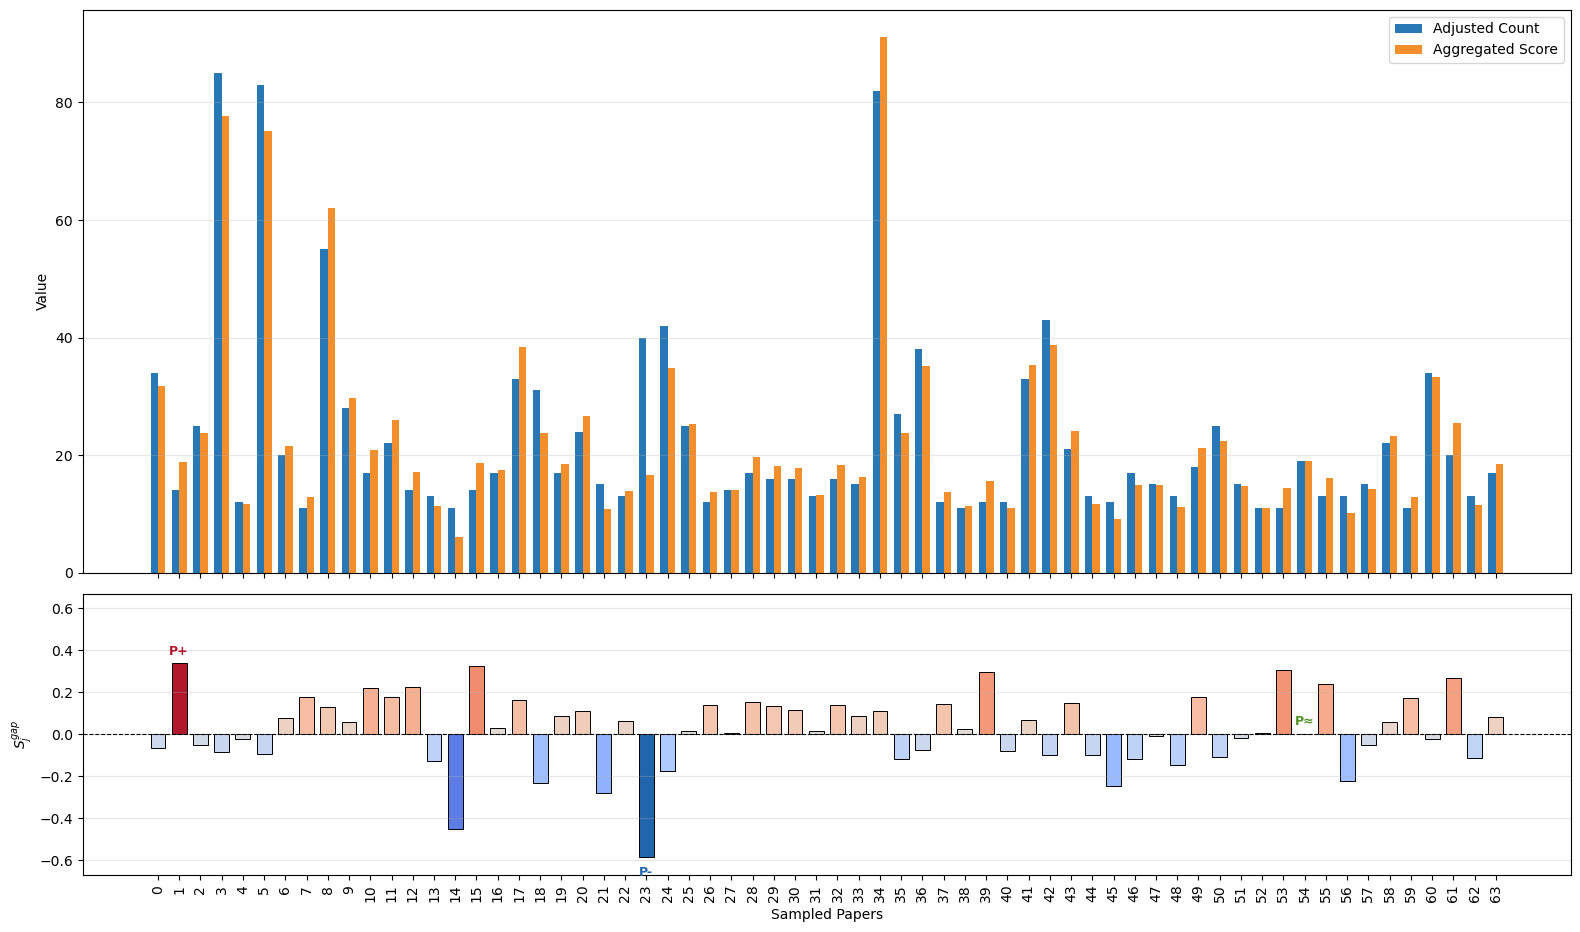

In [48]:
def plot_count_score_comparison( paper_df):
    df = paper_df.copy().reset_index(drop=True)

    x = np.arange(len(df))
    width = 0.35

    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=(16, 10),
        sharex=True,
        gridspec_kw={
            "height_ratios": [2, 1],
            "hspace": 0.05,
        },
    )
    fig.subplots_adjust(
        left=0.065,
        right=0.995,
        top=0.985,
        bottom=0.12,
        hspace=0.08,
    )

    # (a) Count and normalized score
    ax1.bar(
        x - width / 2,
        df["count"],
        width,
        label="Adjusted Count",
        color="#2878B5",
    )

    ax1.bar(
        x + width / 2,
        df["total_score"],
        width,
        label="Aggregated Score",
        color="#F28E2B",
    )

    ax1.set_ylabel("Value")
    ax1.legend()
    ax1.grid(axis="y", alpha=0.3)

    # (b) Relative gap
    limit = max(
        abs(df["diff"].min()),
        abs(df["diff"].max()),
    )

    if limit == 0:
        limit = 0.1

    norm = plt.Normalize(-limit, limit)
    colors = plt.cm.coolwarm(norm(df["diff"]))

    case_colors = {
        "largest_positive_gap": "#B2182B",
        "largest_negative_gap": "#2166AC",
        "closest_to_equal": "#4D9221",
    }

    case_labels = {
        "largest_positive_gap": "P+",
        "largest_negative_gap": "P-",
        "closest_to_equal": "P≈",
    }

    for index, case in enumerate(df["case"]):
        if case:
            colors[index] = plt.matplotlib.colors.to_rgba(
                case_colors[case]
            )

    ax2.bar(
        x,
        df["diff"],
        width=0.7,
        color=colors,
        edgecolor="black",
        linewidth=0.7,
    )

    ax2.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8,
    )

    for index, row in df.iterrows():
        if not row["case"]:
            continue

        offset = 6 if row["diff"] >= 0 else -14

        ax2.annotate(
            case_labels[row["case"]],
            xy=(index, row["diff"]),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="bold",
            color=case_colors[row["case"]],
        )

    ax2.set_ylabel(r"$S^{gap}_j$")
    ax2.set_xlabel("Sampled Papers")
    ax2.set_ylim(-limit * 1.15, limit * 1.15)
    ax2.grid(axis="y", alpha=0.3)

    ax2.set_xticks(x)
    ax2.set_xticklabels(
        x,
        rotation=90
    )

    # plt.tight_layout()

    plt.show()

plot_count_score_comparison(result["papers"])

## detail

In [95]:
def plot_count_score_detail(
    citation_df,
    paper_id
):
    paper_id = int(paper_id)

    df = citation_df[
        citation_df["cited_id"] == paper_id
    ].copy()

    if df.empty:
        raise ValueError(
            f"No citation data found for paper {paper_id}."
        )

    df = df.sort_values(
        [
            "citing_publication_date",
            "citing_year",
            "citing_id",
        ],
        na_position="last",
    ).reset_index(drop=True)

    df["count_sum"] = df["count"].cumsum()
    df["score_sum"] = df["score_mm"].cumsum()
    df["cross_sum"] = df["cross_mm"].cumsum()
    df["llm_sum"] = df["llm_mm"].cumsum()
    df["delta"] = df["score_mm"] - df["count"]

    # 按最终 alpha 展示实际语义组成
    df["cross_component"] = (
        0.2 * df["cross_score"]
    )
    df["llm_component"] = (
        0.8 * df["llm_score"]
    )

    x = np.arange(1, len(df) + 1)

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(10, 4.8),
        gridspec_kw={
            "height_ratios": [2, 1, 1],
        },
    )

    # (a) Cumulative values
    axes[0].step(
        x,
        df["count_sum"],
        where="post",
        label="Adjusted Count",
        color="#9467BD",
    )

    axes[0].plot(
        x,
        df["score_sum"],
        label="Aggregated Score",
        color="#D62728",
    )

    axes[0].plot(
        x,
        df["cross_sum"],
        label="Cross-encoder-only",
        color="#1F77B4",
    )

    axes[0].plot(
        x,
        df["llm_sum"],
        label="LLM-only",
        color="#FF7F0E",
    )

    axes[0].set_ylabel("Count & Score")
    axes[0].set_title(
        "(a) Cumulative Adjusted Count & Aggregated Score",loc="left"
    )
    axes[0].tick_params(labelbottom=False)
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # (b) Per-citation deviation
    delta_limit = max(
        abs(df["delta"].min()),
        abs(df["delta"].max()),
    )

    if delta_limit == 0:
        delta_limit = 0.1

    delta_norm = plt.Normalize(
        -delta_limit,
        delta_limit,
    )

    axes[1].bar(
        x,
        df["delta"],
        color=plt.cm.coolwarm(
            delta_norm(df["delta"])
        ),
        edgecolor="black",
        linewidth=0.7,
    )

    axes[1].axhline(
        0,
        linestyle="--",
        color="black",
        linewidth=0.8,
    )

    axes[1].set_ylabel(
        r"$\tilde{S}_{ij}-N_{ij}$"
    )
    axes[1].set_title(
        "(b) Per-citation Score Deviation",loc="left"
    )
    axes[1].tick_params(labelbottom=False)
    axes[1].grid(alpha=0.3)

    # (c) Actual score components
    axes[2].bar(
        x,
        df["cross_component"],
        label="Cross-encoder",
        color="#1F77B4",
    )

    axes[2].bar(
        x,
        df["llm_component"],
        bottom=df["cross_component"],
        label="LLM",
        color="#FF7F0E",
    )

    axes[2].bar(
        x,
        df["author_penalty"],
        label="Author Penalty",
        color="#2CA02C",
    )

    axes[2].axhline(
        1,
        linestyle="--",
        color="black",
        linewidth=0.8,
        alpha=0.6,
    )

    axes[2].set_xlabel("Citation Sequence")
    axes[2].set_ylabel("Score")
    axes[2].set_title(
        "(c) Score Components",
        loc="left",
        y=1.13,
        pad=0,
    )
    axes[2].legend(
        ncol=3,
        loc="upper right",
        bbox_to_anchor=(1.0, 1.3),
        bbox_transform=axes[2].transAxes,
        borderaxespad=0,
        frameon=False,
        handlelength=1.2,
        handletextpad=0.4,
        columnspacing=0.9
    )
    axes[2].grid(alpha=0.3)

    plt.tight_layout()

    # fig.subplots_adjust(
    #     left=0.09,
    #     right=0.99,
    #     top=0.97,
    #     bottom=0.10,
    #     hspace=0.55,
    # )

    plt.show()

    return df


In [18]:
display(
    result["cases"][
        [
            "case",
            "cited_id",
            "cited_title",
            "count",
            "total_score",
            "diff",
        ]
    ]
)

,case,cited_id,cited_title,count,total_score,diff
2,largest_positive_gap,265325086,A Novel Microstrip Sensor Based on Closed Loop...,14,18.760448,0.340032
35,largest_negative_gap,268432321,A comprehensive review of leveraging cloud-nat...,40,16.677605,-0.583060
73,closest_to_equal,271733209,"Aging, Cancer, and Inflammation: The Telomeras...",19,19.071283,0.003752


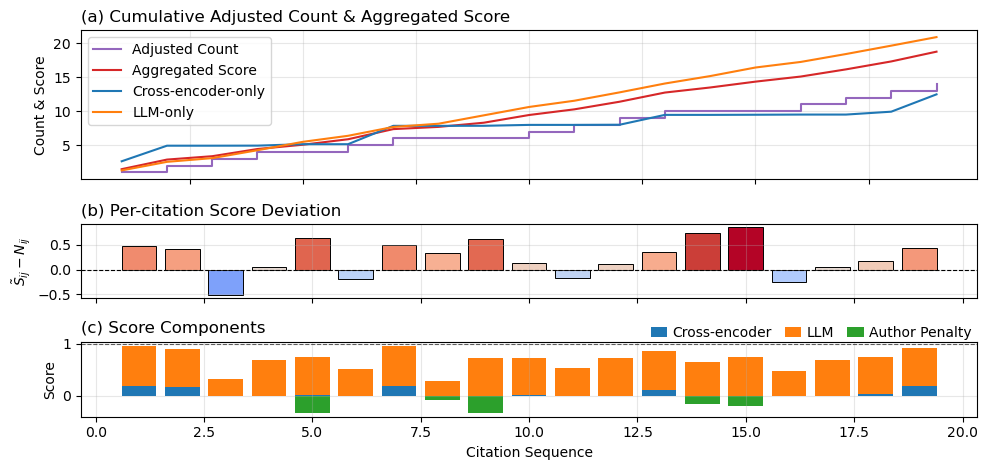

In [96]:
df = plot_count_score_detail(result["citations"], 265325086)

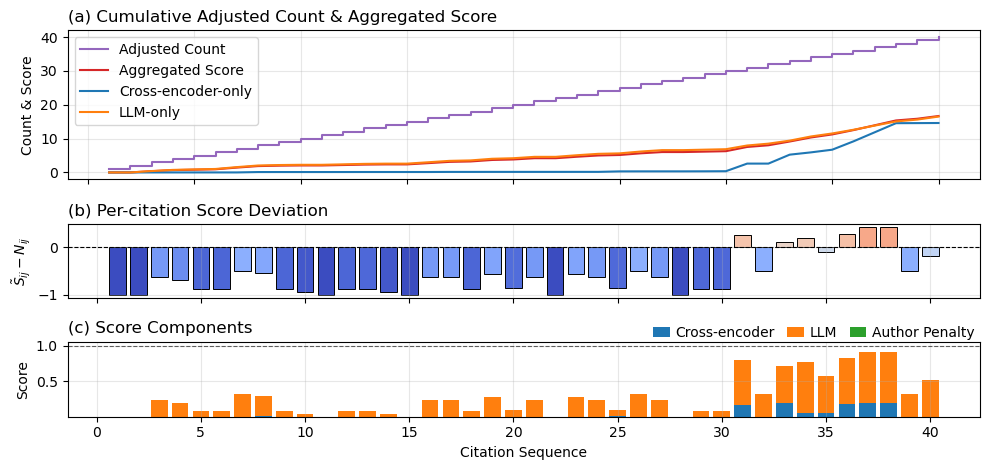

In [97]:
df = plot_count_score_detail(result["citations"], 268432321)

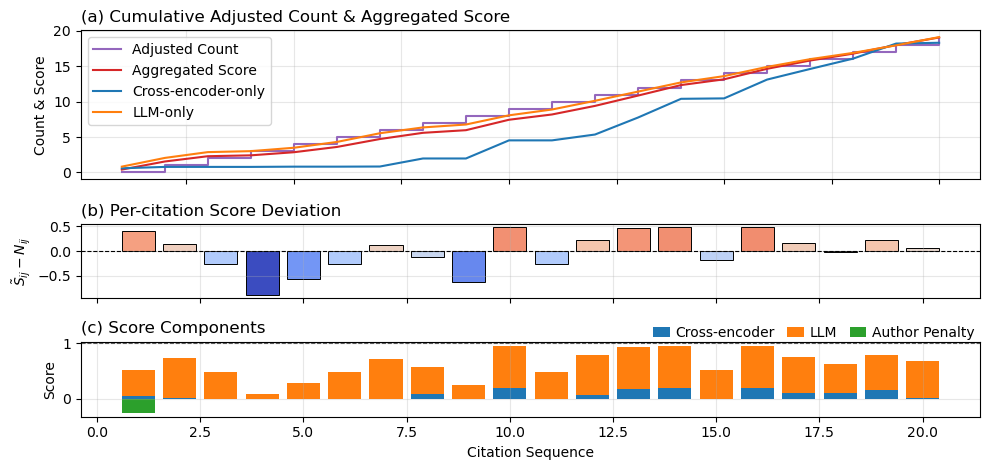

In [98]:
df = plot_count_score_detail(result["citations"], 271733209)